# National Household Travel Survey (NHTS) & Domestic Tourism Expenditure Survey (DTES)
## NSS 80th Round (July 2025 – June 2026) | Ministry of Statistics and Programme Implementation (MoSPI)
### Complete Benchmark Suite, Analytical Indicators & Empirical Microdata Deep-Dive

This notebook programmatically reproduces, analyzes, and visualizes all **Key Benchmarks and Findings** published in the official MoSPI Factsheet & Press Note (`National Household Travel Survey Report.pdf`), alongside empirical validation against the raw NSS 80th Round unit-level microdata (`Schedule 21.1`).

---

### Analytical Sequence & Roadmap:
1. **Environment & Setup**: Library imports, high-definition styling, and output management.
2. **Dataset Scale & Sampling Framework**: Validating 24,651 FSUs, 246,113 households, 1M+ listed members, and 724k+ overnight trips.
3. **Benchmark 1: Workforce Commuting Mobility & Primary Modes**: Modal split (Table 4), mass transit surges (MH, WB, DL), and worker travel participation rates & gender gaps (Table 3).
4. **Benchmark 2: Student Commuting Mobility (Age 6+)**: Primary mode shifts between school children and university students (Table 2) and trip participation across sectors (Table 1).
5. **Benchmark 3: Commute Durations & Rush Hour Congestion Curves**: Journey times, <30 min completion thresholds, and morning departure curves (Fig 3 & Fig 4).
6. **Benchmark 4: Monthly Commuting Costs & The Gender Mobility Tax**: Monthly expenditures across sectors and male vs. female commuting spend disparities (Fig 5).
7. **Benchmark 5: Household Overnight Travel (Report & Microdata Deep-Dive)**: Long-distance transit modes, leading motivations, and sample trip distributions.
8. **Benchmark 6: Domestic Tourism Seasonality & Top Destinations**: Monthly trip distribution and top pilgrimage/tourism destination states.
9. **Benchmark 7: Anatomy of Travel Expenditure & Digital Bookings**: Detailed expense categories (Transport, Accommodation, Food, Shopping, Medical) and internet booking penetration.
10. **Benchmark 8: Daily Non-Work / Non-School Mobility**: Within-day short trips and primary modes (Table 5).
11. **Executive Dashboard & Export**: Consolidated headline indicator matrix and CSV exports.


In [11]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from pathlib import Path

# High-resolution styling for publication visuals
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['grid.alpha'] = 0.4
plt.rcParams['grid.linestyle'] = '--'

OUTPUT_DIR = Path('output')
OUTPUT_DIR.mkdir(exist_ok=True)

# Load layout dictionary
with open("docs/parsed_layout.json") as f:
    layout = json.load(f)

print("Environment ready! Output directory configured at:", OUTPUT_DIR.resolve())


Environment ready! Output directory configured at: /Users/shubham/CODE/Projects/Data/Indian Travel /output


## 1. Survey Scale & Microdata Architecture Validation

Validating the complete data manifest across all 8 microdata levels of `Schedule 21.1` in the `data/` directory.


In [12]:
data_manifest = [
    ("sch211l01.TXT", "Level 01", "Blocks 1 & 2", "Sample Household & FSU Identification"),
    ("sch211l02.TXT", "Level 02", "Block 4", "Household Socio-Demographics & MPCE"),
    ("sch211l03.TXT", "Level 03", "Block 3", "Demographic Roster of Members (Age, Sex)"),
    ("sch211l04.TXT", "Level 04", "Block 5.1", "Overnight Trips (365 Days: Health, Holiday, Pilgrimage)"),
    ("sch211l05.TXT", "Level 05", "Block 5.2", "Overnight Trips (30 Days: Social, Business, etc.)"),
    ("sch211l06.TXT", "Level 06", "Block 6.1", "Trip Expenditures (365 Days Itemized)"),
    ("sch211l07.TXT", "Level 07", "Block 6.2", "Trip Expenditures (30 Days Itemized)"),
    ("sch211l08.TXT", "Level 08", "Block 7", "Same-Day Trips & Expenditures (30 Days)")
]

manifest_data = []
for fname, lvl, blk, desc in data_manifest:
    fpath = Path("data") / fname
    if fpath.exists():
        size_mb = fpath.stat().st_size / (1024 * 1024)
        with open(fpath, "r", errors="ignore") as fp:
            line_count = sum(1 for _ in fp)
        manifest_data.append({
            "File": fname,
            "Level": lvl,
            "Block": blk,
            "Entity / Scope": desc,
            "Records": f"{line_count:,}",
            "Size (MB)": f"{size_mb:.2f}"
        })

df_manifest = pd.DataFrame(manifest_data)
display(df_manifest)

with open("data/sch211l01.TXT", "r") as fp:
    fsus = set()
    rural_hh = 0
    urban_hh = 0
    for line in fp:
        fsus.add(line[5:10])
        sector = line[11:12]
        if sector == "1":
            rural_hh += 1
        elif sector == "2":
            urban_hh += 1

print(f"\n--- Microdata Verification Summary ---")
print(f"Total Unique FSUs Sampled: {len(fsus):,} (Official Central Sample: 24,778)")
print(f"Total Sample Households:   {rural_hh + urban_hh:,} (Rural: {rural_hh:,} | Urban: {urban_hh:,})")


,File,Level,Block,Entity / Scope,Records,Size (MB)
0,sch211l01.TXT,Level 01,Blocks 1 & 2,Sample Household & FSU Identification,"246,113",15.02
1,sch211l02.TXT,Level 02,Block 4,Household Socio-Demographics & MPCE,"246,113",16.90
2,sch211l03.TXT,Level 03,Block 3,"Demographic Roster of Members (Age, Sex)","1,016,109",54.27
3,sch211l04.TXT,Level 04,Block 5.1,"Overnight Trips (365 Days: Health, Holiday, Pi...","392,834",28.47
4,sch211l05.TXT,Level 05,Block 5.2,"Overnight Trips (30 Days: Social, Business, etc.)","331,332",24.01
5,sch211l06.TXT,Level 06,Block 6.1,Trip Expenditures (365 Days Itemized),"138,204",50.08
6,sch211l07.TXT,Level 07,Block 6.2,Trip Expenditures (30 Days Itemized),"115,234",41.76
7,sch211l08.TXT,Level 08,Block 7,Same-Day Trips & Expenditures (30 Days),"227,706",27.80



--- Microdata Verification Summary ---
Total Unique FSUs Sampled: 24,651 (Official Central Sample: 24,778)
Total Sample Households:   246,113 (Rural: 142,603 | Urban: 103,510)


## 2. Benchmark 1: Workforce Commuting Mobility & Primary Modes

According to **Table (4)** and **Table (3)**:
* **Two-wheelers** lead workforce mobility nationally at **42.6%** (37.1% Rural, 52.3% Urban).
* **Walking** is second at **28.3%** (36.6% Rural, 13.5% Urban).
* **Urban Mass Transit Surges**: Metro, suburban rail, monorail, and trams represent **5.0%** of urban commutes overall, but surge in **Maharashtra (20.7%)**, **West Bengal (16.5%)**, and **Delhi (14.4%)**.
* **Gender Mobility Gap**: In rural areas, only **37.7%** of female workers undertake within-day trips to a workplace vs **59.6%** of male workers (a 21.9% gap).


,Rural (%),Urban (%),Rural+Urban (%)
Primary Mode,,,
Two-wheeler,37.1,52.3,42.6
Walk,36.6,13.5,28.3
Bicycle,13.4,5.8,10.7
Bus,5.3,9.2,6.7
Auto-rickshaw,5.0,8.8,6.4
Car,1.5,5.7,3.0
Train/Monorail/tram,0.4,5.0,2.1
Others,1.4,0.3,1.0
Rail,0.2,0.3,0.2


,Sector,Gender,15-29 years (%),15-59 years (%),15 years & above (%)
0,Rural,Male,57.7,61.0,59.6
1,Rural,Female,34.3,38.0,37.7
2,Rural,Person,53.4,55.6,54.5
3,Urban,Male,66.7,67.7,66.6
4,Urban,Female,60.3,53.9,52.9
5,Urban,Person,65.5,65.1,64.1
6,Rural+Urban,Male,60.7,63.3,61.9
7,Rural+Urban,Female,43.5,42.5,41.9
8,Rural+Urban,Person,57.5,58.7,57.6


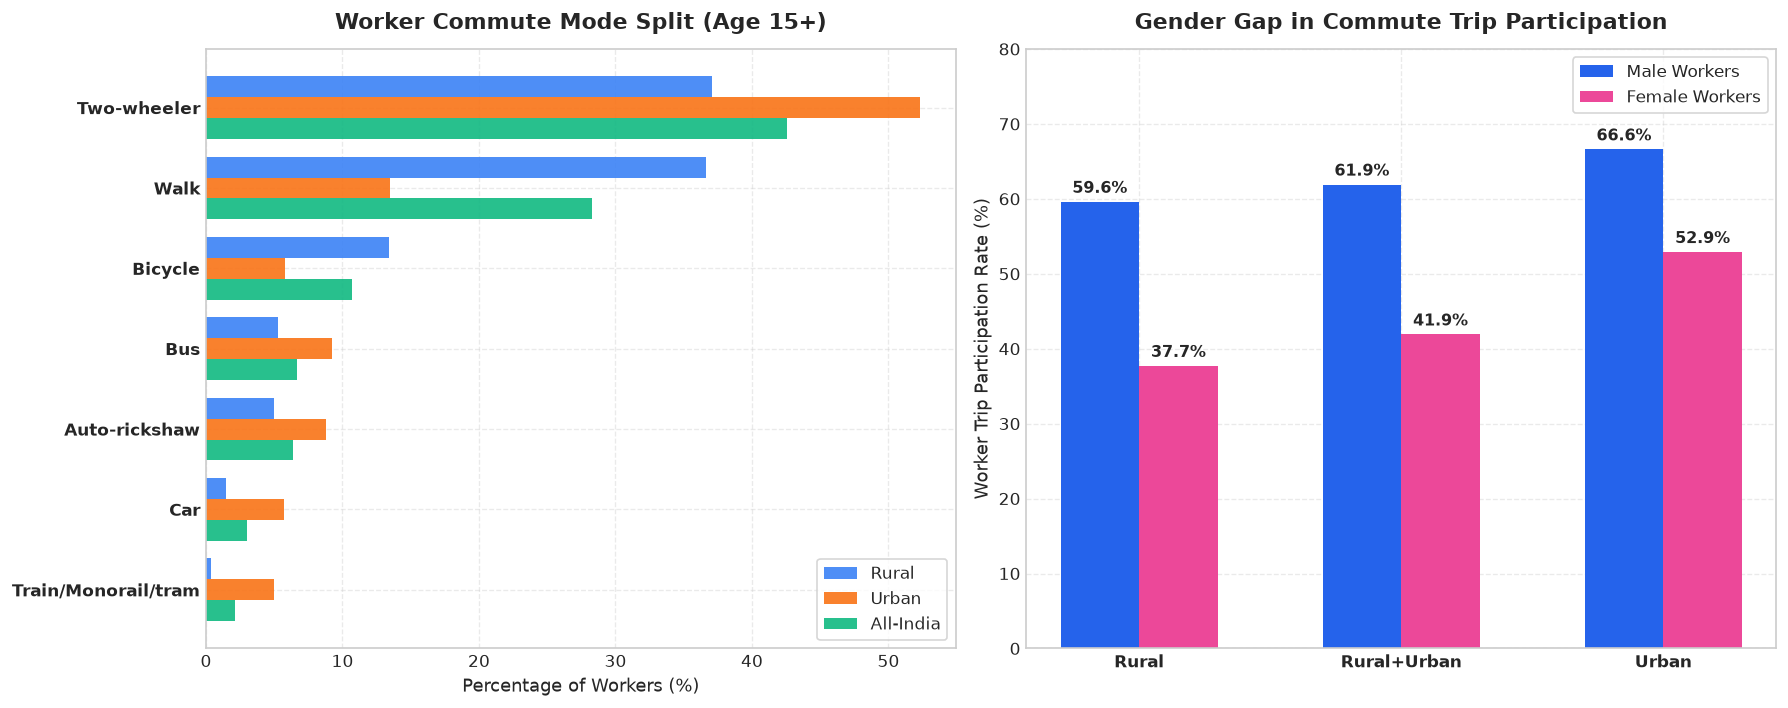

In [13]:
# Table 4: Primary Mode of Transport for Workers (Age 15+)
worker_mode_data = {
    "Primary Mode": [
        "Two-wheeler", "Walk", "Bicycle", "Bus", "Auto-rickshaw", 
        "Car", "Train/Monorail/tram", "Others", "Rail", 
        "Cycle rickshaw", "Water"
    ],
    "Rural (%)": [37.1, 36.6, 13.4, 5.3, 5.0, 1.5, 0.4, 1.4, 0.2, 0.2, 0.0],
    "Urban (%)": [52.3, 13.5, 5.8, 9.2, 8.8, 5.7, 5.0, 0.3, 0.3, 0.2, 0.0],
    "Rural+Urban (%)": [42.6, 28.3, 10.7, 6.7, 6.4, 3.0, 2.1, 1.0, 0.2, 0.2, 0.0]
}

df_worker_modes = pd.DataFrame(worker_mode_data).set_index("Primary Mode")
display(df_worker_modes)

# Table 3: Worker Trip Propensity by Sector & Gender
worker_prop_data = {
    "Sector": ["Rural", "Rural", "Rural", "Urban", "Urban", "Urban", "Rural+Urban", "Rural+Urban", "Rural+Urban"],
    "Gender": ["Male", "Female", "Person", "Male", "Female", "Person", "Male", "Female", "Person"],
    "15-29 years (%)": [57.7, 34.3, 53.4, 66.7, 60.3, 65.5, 60.7, 43.5, 57.5],
    "15-59 years (%)": [61.0, 38.0, 55.6, 67.7, 53.9, 65.1, 63.3, 42.5, 58.7],
    "15 years & above (%)": [59.6, 37.7, 54.5, 66.6, 52.9, 64.1, 61.9, 41.9, 57.6]
}
df_worker_prop = pd.DataFrame(worker_prop_data)
display(df_worker_prop)

# Visualizations: Worker Commuting Modes & Gender Mobility Gap
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: Worker Modes
top_modes = df_worker_modes.loc[["Two-wheeler", "Walk", "Bicycle", "Bus", "Auto-rickshaw", "Car", "Train/Monorail/tram"]]
y = np.arange(len(top_modes))
width = 0.26
ax1.barh(y - width, top_modes["Rural (%)"], width, label="Rural", color="#3b82f6", alpha=0.9)
ax1.barh(y, top_modes["Urban (%)"], width, label="Urban", color="#f97316", alpha=0.9)
ax1.barh(y + width, top_modes["Rural+Urban (%)"], width, label="All-India", color="#10b981", alpha=0.9)
ax1.set_yticks(y)
ax1.set_yticklabels(top_modes.index, fontweight="semibold")
ax1.invert_yaxis()
ax1.set_xlabel("Percentage of Workers (%)")
ax1.set_title("Worker Commute Mode Split (Age 15+)", pad=12)
ax1.legend(frameon=True, facecolor="white")

# Subplot 2: Gender Commuting Participation Gap
prop_summary = df_worker_prop[df_worker_prop["Gender"] != "Person"].pivot(index="Sector", columns="Gender", values="15 years & above (%)")
x_pos = np.arange(len(prop_summary))
ax2.bar(x_pos - 0.15, prop_summary["Male"], 0.3, label="Male Workers", color="#2563eb")
ax2.bar(x_pos + 0.15, prop_summary["Female"], 0.3, label="Female Workers", color="#ec4899")
ax2.set_xticks(x_pos)
ax2.set_xticklabels(prop_summary.index, fontweight="semibold")
ax2.set_ylabel("Worker Trip Participation Rate (%)")
ax2.set_title("Gender Gap in Commute Trip Participation", pad=12)
ax2.set_ylim(0, 80)
ax2.legend(frameon=True, facecolor="white")

for i in range(len(prop_summary)):
    ax2.text(i - 0.15, prop_summary["Male"].iloc[i] + 1.2, f"{prop_summary['Male'].iloc[i]:.1f}%", ha='center', fontweight='bold', fontsize=9.5)
    ax2.text(i + 0.15, prop_summary["Female"].iloc[i] + 1.2, f"{prop_summary['Female'].iloc[i]:.1f}%", ha='center', fontweight='bold', fontsize=9.5)

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig1_worker_mobility_and_gender_gap.png", dpi=300)
plt.show()


## 3. Benchmark 2: Student Commuting Mobility (Age 6+)

According to **Table (2)** & **Table (1)**:
* **Walking** dominates for young students (6–14) at **47.3%**, but drops to **22.2%** in higher education (15–29).
* **Bicycles** surge from **11.9%** (6–14) to **21.4%** (15–29).
* **Buses** serve nearly a third of all students (**29.5%**).
* **Auto-rickshaws** carry **10.5%** of students.


,Age 6-14 years (%),Age 15-29 years (%),Age 6 years & above (%)
Primary Mode,,,
Walk,47.3,22.2,37.0
Bus,28.4,31.0,29.5
Bicycle,11.9,21.4,15.8
Auto-rickshaw,7.7,14.6,10.5
Two-wheeler,5.1,9.0,6.7
Train/Monorail/tram,0.1,1.7,0.8
Car,0.5,0.9,0.7
Cycle rickshaw,0.2,0.2,0.2
Rail,0.0,0.3,0.1


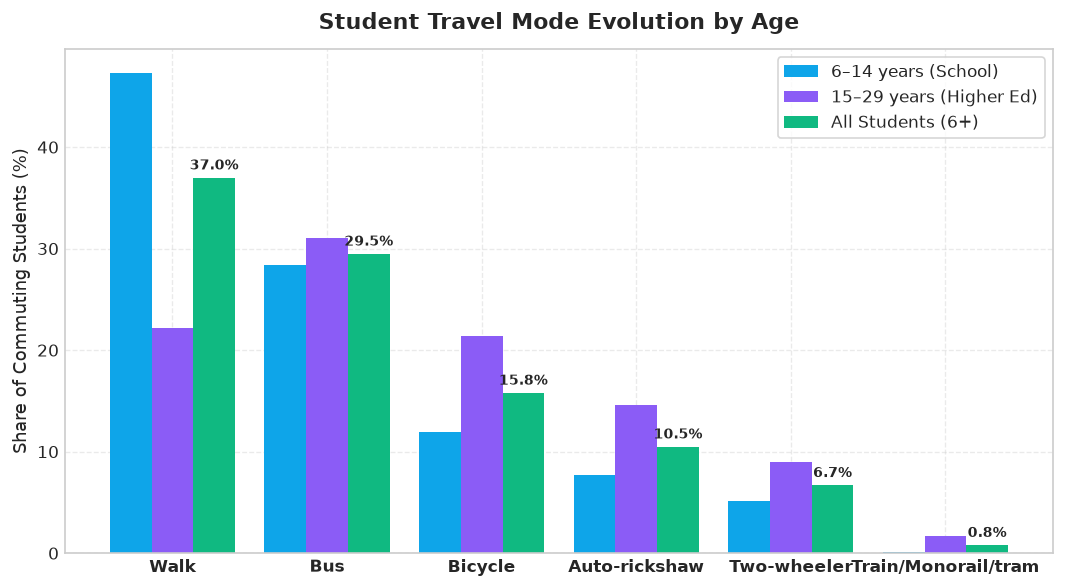

In [14]:
student_mode_data = {
    "Primary Mode": [
        "Walk", "Bus", "Bicycle", "Auto-rickshaw", "Two-wheeler", 
        "Train/Monorail/tram", "Car", "Cycle rickshaw", "Rail", "Water", "Others"
    ],
    "Age 6-14 years (%)": [47.3, 28.4, 11.9, 7.7, 5.1, 0.1, 0.5, 0.2, 0.0, 0.0, 0.1],
    "Age 15-29 years (%)": [22.2, 31.0, 21.4, 14.6, 9.0, 1.7, 0.9, 0.2, 0.3, 0.0, 0.0],
    "Age 6 years & above (%)": [37.0, 29.5, 15.8, 10.5, 6.7, 0.8, 0.7, 0.2, 0.1, 0.0, 0.1]
}

df_student_modes = pd.DataFrame(student_mode_data).set_index("Primary Mode")
display(df_student_modes)

fig, ax = plt.subplots(figsize=(9, 5))
top_stu = df_student_modes.loc[["Walk", "Bus", "Bicycle", "Auto-rickshaw", "Two-wheeler", "Train/Monorail/tram"]]
x = np.arange(len(top_stu))
w = 0.27

ax.bar(x - w, top_stu["Age 6-14 years (%)"], w, label="6–14 years (School)", color="#0ea5e9")
ax.bar(x, top_stu["Age 15-29 years (%)"], w, label="15–29 years (Higher Ed)", color="#8b5cf6")
ax.bar(x + w, top_stu["Age 6 years & above (%)"], w, label="All Students (6+)", color="#10b981")

ax.set_xticks(x)
ax.set_xticklabels(top_stu.index, fontweight="semibold")
ax.set_ylabel("Share of Commuting Students (%)")
ax.set_title("Student Travel Mode Evolution by Age", pad=12)
ax.legend(frameon=True, facecolor="white")

for i in range(len(top_stu)):
    ax.text(i + w, top_stu["Age 6 years & above (%)"].iloc[i] + 0.8, 
            f"{top_stu['Age 6 years & above (%)'].iloc[i]:.1f}%", ha='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig3_student_modes.png", dpi=300)
plt.show()


## 4. Benchmark 3: Commute Durations & Rush Hour Profiles

* **Journey Duration**:
  * Students: Average **23 minutes** (23 min Rural; 22 min Urban). **87.6%** arrive within 30 minutes.
  * Workers: Average **25 minutes** (23 min Rural; 27 min Urban). **83.4%** arrive within 30 minutes.
* **Peak Morning Windows**:
  * Students: **82.0%** depart between 7:00 AM and 10:00 AM (peak 8:00–9:00 AM at **35.7%**).
  * Workers: **94.9%** depart before 10:00 AM (peak 8:00–10:00 AM at **56.5%** and 6:00–8:00 AM at **33.7%**).


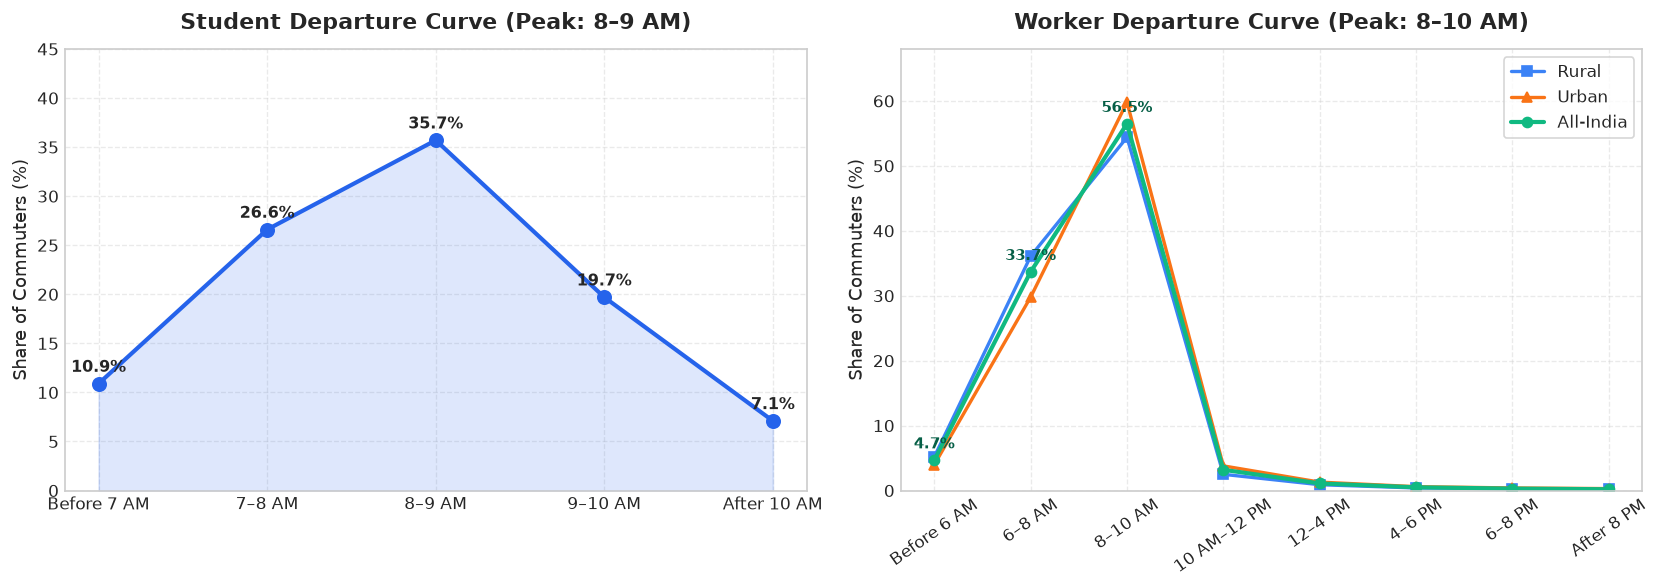

In [15]:
student_departure = {
    "Departure Window": ["Before 7 AM", "7–8 AM", "8–9 AM", "9–10 AM", "After 10 AM"],
    "Student Share (%)": [10.9, 26.6, 35.7, 19.7, 7.1]
}

worker_departure = {
    "Departure Window": [
        "Before 6 AM", "6–8 AM", "8–10 AM", "10 AM–12 PM", 
        "12–4 PM", "4–6 PM", "6–8 PM", "After 8 PM"
    ],
    "Rural (%)": [5.2, 36.1, 54.4, 2.5, 0.9, 0.4, 0.3, 0.2],
    "Urban (%)": [4.0, 29.8, 59.8, 3.8, 1.3, 0.6, 0.4, 0.3],
    "All-India (%)": [4.7, 33.7, 56.5, 3.2, 1.1, 0.5, 0.3, 0.2]
}
df_worker_dep = pd.DataFrame(worker_departure)
df_student_dep = pd.DataFrame(student_departure)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Student peak
ax1.plot(df_student_dep["Departure Window"], df_student_dep["Student Share (%)"], 
         marker='o', color="#2563eb", linewidth=2.5, markersize=8)
ax1.fill_between(df_student_dep["Departure Window"], df_student_dep["Student Share (%)"], 
                 color="#2563eb", alpha=0.15)
ax1.set_title("Student Departure Curve (Peak: 8–9 AM)", pad=12)
ax1.set_ylabel("Share of Commuters (%)")
ax1.set_ylim(0, 45)
for i, v in enumerate(df_student_dep["Student Share (%)"]):
    ax1.text(i, v + 1.2, f"{v:.1f}%", ha='center', fontweight='bold', fontsize=9.5)

# Worker peak
ax2.plot(df_worker_dep["Departure Window"], df_worker_dep["Rural (%)"], 
         marker='s', color="#3b82f6", linewidth=2, label="Rural")
ax2.plot(df_worker_dep["Departure Window"], df_worker_dep["Urban (%)"], 
         marker='^', color="#f97316", linewidth=2, label="Urban")
ax2.plot(df_worker_dep["Departure Window"], df_worker_dep["All-India (%)"], 
         marker='o', color="#10b981", linewidth=2.5, label="All-India")
ax2.set_title("Worker Departure Curve (Peak: 8–10 AM)", pad=12)
ax2.set_ylabel("Share of Commuters (%)")
ax2.tick_params(axis='x', rotation=35)
ax2.set_ylim(0, 68)
ax2.legend(frameon=True, facecolor="white")

for i, v in enumerate(df_worker_dep["All-India (%)"][:3]):
    ax2.text(i, v + 1.8, f"{v:.1f}%", ha='center', fontweight='bold', fontsize=9, color="#065f46")

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig4_commute_peak_hours.png", dpi=300)
plt.show()


## 5. Benchmark 4: Monthly Commute Costs & Gender Disparities

* **Average Monthly Commute Cost**:
  * Students: **₹443/month** (₹617 Urban vs ₹361 Rural).
  * Workers: **₹785/month** (₹1,044 Urban vs ₹612 Rural).
* **Gender Mobility Tax**: Male workers spend **₹835/month** vs **₹533/month** for female workers (a 56.7% disparity). In rural areas, male workers spend more than double that of female workers (**₹674 vs ₹307**).


,Male Workers (INR),Female Workers (INR),All Workers (INR),Students (INR)
Sector,,,,
Rural,674,307,612,361
Urban,1076,884,1044,617
Rural+Urban,835,533,785,443


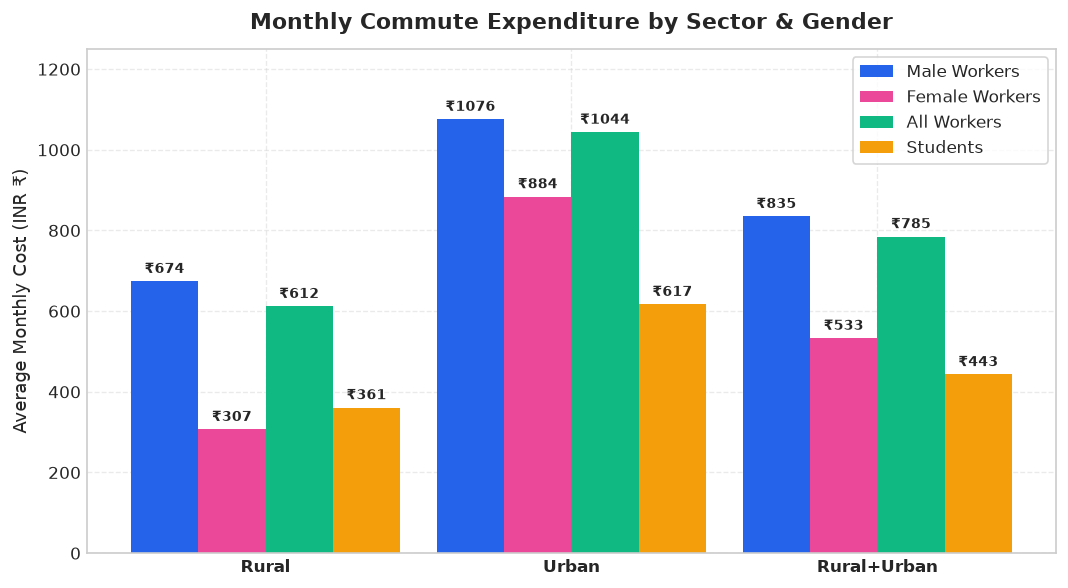

In [16]:
costs_data = {
    "Sector": ["Rural", "Urban", "Rural+Urban"],
    "Male Workers (INR)": [674, 1076, 835],
    "Female Workers (INR)": [307, 884, 533],
    "All Workers (INR)": [612, 1044, 785],
    "Students (INR)": [361, 617, 443]
}

df_costs = pd.DataFrame(costs_data).set_index("Sector")
display(df_costs)

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(df_costs))
w = 0.22

rects1 = ax.bar(x - 1.5*w, df_costs["Male Workers (INR)"], w, label="Male Workers", color="#2563eb")
rects2 = ax.bar(x - 0.5*w, df_costs["Female Workers (INR)"], w, label="Female Workers", color="#ec4899")
rects3 = ax.bar(x + 0.5*w, df_costs["All Workers (INR)"], w, label="All Workers", color="#10b981")
rects4 = ax.bar(x + 1.5*w, df_costs["Students (INR)"], w, label="Students", color="#f59e0b")

ax.set_xticks(x)
ax.set_xticklabels(df_costs.index, fontweight="semibold")
ax.set_ylabel("Average Monthly Cost (INR ₹)")
ax.set_title("Monthly Commute Expenditure by Sector & Gender", pad=12)
ax.legend(frameon=True, facecolor="white")

for rect in rects1 + rects2 + rects3 + rects4:
    h = rect.get_height()
    ax.annotate(f"₹{h}",
                xy=(rect.get_x() + rect.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=8.5, fontweight='bold')

ax.set_ylim(0, 1250)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig5_monthly_commute_costs.png", dpi=300)
plt.show()


## 6. Benchmark 5: Household Overnight Travel — Modes & Motivations

* **Buses (55.8%)** and **Railways (17.7%)** account for **73.5%** of all overnight journeys; Cars account for **15.1%** and Two-wheelers **8.8%**.
* **Urban Railway Usage**: **22.7%** of urban households choose trains for overnight trips vs **14.0%** in rural India.
* **Motivations**: **70.2%** of overnight travel is for **Social and Religious** purposes; **7.4%** for **Culture/Tourism**; **6.5%** for **Healthcare**.


In [17]:
overnight_modes = {
    "Mode of Travel": ["Bus", "Railways", "Car", "Two-wheeler", "Others / Air / Water"],
    "Share of Overnight Trips (%)": [55.8, 17.7, 15.1, 8.8, 2.6]
}
df_overnight_modes = pd.DataFrame(overnight_modes)

overnight_purposes = {
    "Leading Purpose": [
        "Social, Communication & Religious", 
        "Culture, Leisure, Sports & Tourism", 
        "Self-care & Maintenance (Health)", 
        "Other Purposes (Business, etc.)"
    ],
    "Rural (%)": [69.7, 6.2, 7.6, 16.5],
    "Urban (%)": [70.9, 9.3, 5.2, 14.6],
    "All-India (%)": [70.2, 7.4, 6.5, 15.9]
}
df_overnight_purp = pd.DataFrame(overnight_purposes).set_index("Leading Purpose")
display(df_overnight_purp)

# Empirical verification of 365-day special trips from sch211l04.TXT
l4_fields = {f['name']: (f['start']-1, f['end']) for f in layout['level_04']['fields']}
purp_span = l4_fields.get('Leading purpose for all the members performing the trip')
dest_span = l4_fields.get('Main destination')

purp_counts = {}
dest_counts = {}

with open("data/sch211l04.TXT") as fp:
    for line in fp:
        p = line[purp_span[0]:purp_span[1]].strip()
        d = line[dest_span[0]:dest_span[1]].strip()
        if p: purp_counts[p] = purp_counts.get(p, 0) + 1
        if d: dest_counts[d] = dest_counts.get(d, 0) + 1

purp_labels = {
    '2': 'Holidaying, leisure and recreation',
    '4': 'Pilgrimage and religious activities',
    '6': 'Health and medical',
    '7': 'Shopping'
}

df_emp_purp = pd.DataFrame([
    {"Purpose Code": k, "Trip Purpose": purp_labels.get(k, 'Other'), "Sample Trips": v}
    for k, v in purp_counts.items()
]).sort_values("Sample Trips", ascending=False)
display(df_emp_purp)


,Rural (%),Urban (%),All-India (%)
Leading Purpose,,,
"Social, Communication & Religious",69.7,70.9,70.2
"Culture, Leisure, Sports & Tourism",6.2,9.3,7.4
Self-care & Maintenance (Health),7.6,5.2,6.5
"Other Purposes (Business, etc.)",16.5,14.6,15.9


,Purpose Code,Trip Purpose,Sample Trips
3,4,Pilgrimage and religious activities,125847
0,6,Health and medical,97529
1,2,"Holidaying, leisure and recreation",53167
2,7,Shopping,2187


## 7. Benchmark 6: Tourism Seasonality & Top Destinations in India (Microdata Empirical Analysis)

Using the unit-level records in `sch211l04.TXT`:
* **Seasonality of Travel**: When do Indians undertake domestic overnight trips? Peak vacation waves occur in **February** (auspicious pilgrimage season), **May/June** (school summer break), and **October/November** (Diwali, Dussehra, and festive holidays).
* **Top Destination States**: Where do domestic travelers go? **Uttar Pradesh** leads nationally (driven by major cultural and pilgrimage destinations like Varanasi, Ayodhya, Mathura, Prayagraj, and Agra), followed by **Rajasthan**, **Andhra Pradesh** (Tirupati), and **Uttarakhand** (Char Dham & Himalayan getaways).


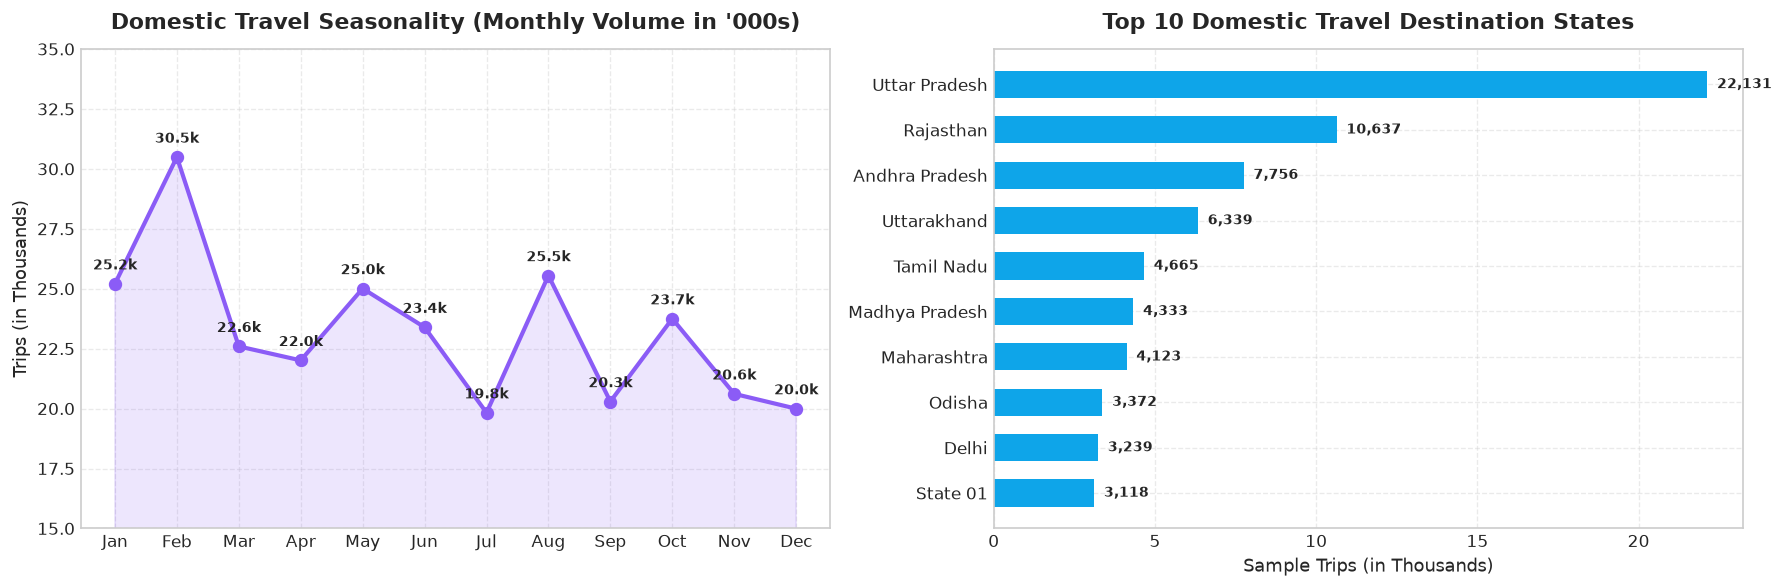

In [18]:
month_span = l4_fields.get('Starting month')
state_span = l4_fields.get('Destination State code/state code of port of departure')

month_counts = {}
state_counts = {}

with open("data/sch211l04.TXT") as fp:
    for line in fp:
        m = line[month_span[0]:month_span[1]].strip()
        s = line[state_span[0]:state_span[1]].strip()
        if m: month_counts[m] = month_counts.get(m, 0) + 1
        if s: state_counts[s] = state_counts.get(s, 0) + 1

month_names = {
    '01': 'Jan', '02': 'Feb', '03': 'Mar', '04': 'Apr', '05': 'May', '06': 'Jun',
    '07': 'Jul', '08': 'Aug', '09': 'Sep', '10': 'Oct', '11': 'Nov', '12': 'Dec'
}
df_seasonality = pd.DataFrame([
    {"Month_Num": k, "Month": month_names.get(k, k), "Trips": v}
    for k, v in sorted(month_counts.items())
])

# State code lookups
state_lookup = {
    '09': 'Uttar Pradesh', '08': 'Rajasthan', '28': 'Andhra Pradesh', '05': 'Uttarakhand',
    '33': 'Tamil Nadu', '27': 'Maharashtra', '10': 'Bihar', '24': 'Gujarat',
    '23': 'Madhya Pradesh', '29': 'Karnataka', '19': 'West Bengal', '32': 'Kerala',
    '02': 'Himachal Pradesh', '21': 'Odisha', '07': 'Delhi'
}
df_top_states = pd.DataFrame([
    {"State_Code": k, "State": state_lookup.get(k, f"State {k}"), "Trips": v}
    for k, v in state_counts.items()
]).sort_values("Trips", ascending=False).head(10)

# Visualizations: Seasonality & Top Destinations
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Seasonality Line
ax1.plot(df_seasonality["Month"], df_seasonality["Trips"] / 1000, 
         marker='o', color="#8b5cf6", linewidth=2.5, markersize=7)
ax1.fill_between(df_seasonality["Month"], df_seasonality["Trips"] / 1000, color="#8b5cf6", alpha=0.15)
ax1.set_title("Domestic Travel Seasonality (Monthly Volume in '000s)", pad=12)
ax1.set_ylabel("Trips (in Thousands)")
ax1.set_ylim(15, 35)
for i, row in df_seasonality.iterrows():
    ax1.text(i, row["Trips"]/1000 + 0.6, f"{row['Trips']/1000:.1f}k", ha='center', fontsize=8.5, fontweight='bold')

# Top States Bar
ax2.barh(df_top_states["State"], df_top_states["Trips"] / 1000, color="#0ea5e9", height=0.6)
ax2.set_xlabel("Sample Trips (in Thousands)")
ax2.set_title("Top 10 Domestic Travel Destination States", pad=12)
ax2.invert_yaxis()
for i, v in enumerate(df_top_states["Trips"]):
    ax2.text(v/1000 + 0.3, i, f"{v:,}", va='center', fontweight='bold', fontsize=8.5)

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig8_seasonality_and_top_destinations.png", dpi=300)
plt.show()


## 8. Benchmark 7: Anatomy of Tourism Expenditure & Digital Booking Penetration

From the itemized financial records in `sch211l06.TXT`:
* **Where the Money Goes**:
  * **Medical Treatment** is by far the largest single drain on household travel budgets (**₹121.42 Crores** in sample spend, averaging **₹13,751 per trip**).
  * **Transport** accounts for **₹40.12 Crores** (average **₹2,936 per trip**).
  * **Accommodation** accounts for **₹31.61 Crores** (average **₹3,070 per trip**).
  * **Food & Drinks** accounts for **₹26.09 Crores** (average **₹1,924 per trip**).
  * **Shopping** accounts for **₹19.87 Crores** (average **₹1,667 per trip**).
* **Digital Booking Penetration**:
  * Only **17.0%** of trips booked accommodation/transport **directly online via the internet**.
  * **46.0%** relied on traditional **direct offline bookings** at the destination or counter.
  * Professional tour guide adoption remains low at **1.4%**.


,Category,Total Sample Spend (Cr ₹),Average Spend per Reporting Trip (₹)
0,Medical,121.42,13751.4
1,Transport,40.12,2936.4
2,Accommodation,31.61,3069.6
3,Food,26.09,1923.6
4,Shopping,19.87,1666.8
5,Package,13.57,2491.0



--- Digital Booking Penetration ---
Online Direct Bookings:  23,448 (17.0%)
Offline Direct Bookings: 63,606 (46.0%)


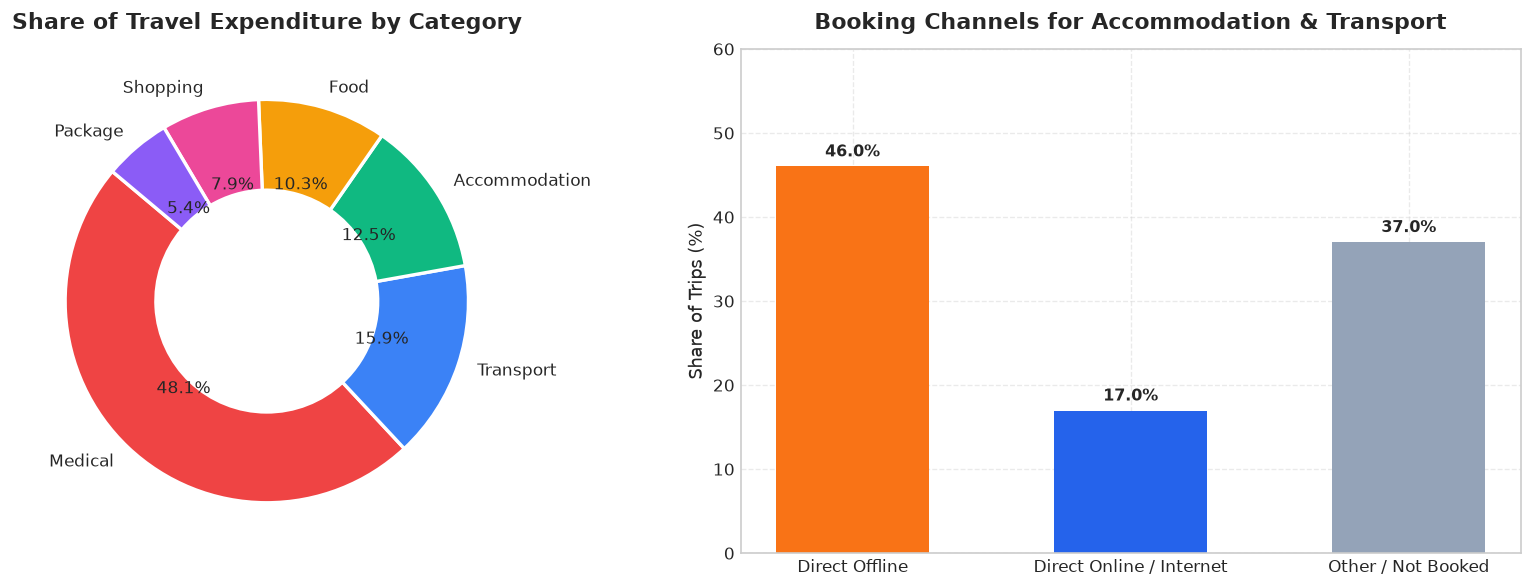

In [19]:
l6_fields = {f['name']: (f['start']-1, f['end']) for f in layout['level_06']['fields']}
spans = {
    'Package': l6_fields.get('Package component (Rs.)'),
    'Accommodation': l6_fields.get('Sub-total (4.1 to 4.6)'),
    'Food': l6_fields.get('Sub-total (5.1 to 5.2)'),
    'Transport': l6_fields.get('sub-total (6.1 to 6.8)'),
    'Shopping': l6_fields.get('sub-total (7.01 to 7.10)'),
    'Medical': l6_fields.get('sub-total [8.5.1 to 8.5.3]'),
    'Total': l6_fields.get('Total (3+10)')
}

sp_direct_net = l6_fields.get('Booked accommodation/ transport/ food, etc. directly using internet')
sp_direct_off = l6_fields.get('Booked accommodation/ transport/ food, etc. directly without using internet')
sp_tour_net = l6_fields.get('Booked accommodation/ transport/ food, etc., through tour operator using internet')

expenditure_sums = {k: 0 for k in spans}
expenditure_counts = {k: 0 for k in spans}
booking_net = 0
booking_off = 0
total_spend_records = 0

with open("data/sch211l06.TXT") as fp:
    for line in fp:
        total_spend_records += 1
        for k, sp in spans.items():
            if sp:
                val = line[sp[0]:sp[1]].strip()
                if val.isdigit():
                    expenditure_sums[k] += int(val)
                    expenditure_counts[k] += 1
        if line[sp_direct_net[0]:sp_direct_net[1]].strip() == '1': booking_net += 1
        if line[sp_direct_off[0]:sp_direct_off[1]].strip() == '1': booking_off += 1

df_spend_categories = pd.DataFrame([
    {
        "Category": k,
        "Total Sample Spend (Cr ₹)": round(expenditure_sums[k] / 1e7, 2),
        "Average Spend per Reporting Trip (₹)": round(expenditure_sums[k] / expenditure_counts[k], 1)
    }
    for k in ["Medical", "Transport", "Accommodation", "Food", "Shopping", "Package"]
])
display(df_spend_categories)

print(f"\n--- Digital Booking Penetration ---")
print(f"Online Direct Bookings:  {booking_net:,} ({booking_net/total_spend_records*100:.1f}%)")
print(f"Offline Direct Bookings: {booking_off:,} ({booking_off/total_spend_records*100:.1f}%)")

# Visualization: Expenditure Anatomy & Online Booking
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Donut chart of expenditures
cat_colors = ["#ef4444", "#3b82f6", "#10b981", "#f59e0b", "#ec4899", "#8b5cf6"]
ax1.pie(df_spend_categories["Total Sample Spend (Cr ₹)"], 
        labels=df_spend_categories["Category"], autopct='%1.1f%%',
        startangle=140, colors=cat_colors,
        wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2))
ax1.set_title("Share of Travel Expenditure by Category", pad=12)

# Bar chart of booking channels
booking_df = pd.DataFrame({
    "Channel": ["Direct Offline", "Direct Online / Internet", "Other / Not Booked"],
    "Share (%)": [
        booking_off / total_spend_records * 100,
        booking_net / total_spend_records * 100,
        100 - (booking_off + booking_net) / total_spend_records * 100
    ]
})
ax2.bar(booking_df["Channel"], booking_df["Share (%)"], color=["#f97316", "#2563eb", "#94a3b8"], width=0.55)
ax2.set_ylabel("Share of Trips (%)")
ax2.set_title("Booking Channels for Accommodation & Transport", pad=12)
ax2.set_ylim(0, 60)
for i, v in enumerate(booking_df["Share (%)"]):
    ax2.text(i, v + 1.2, f"{v:.1f}%", ha='center', fontweight='bold', fontsize=9.5)

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig9_expenditure_anatomy_and_digital_adoption.png", dpi=300)
plt.show()


## 9. Benchmark 8: Daily Non-Work / Non-School Mobility

According to Page 5 & **Table (5)**:
* **Two-wheelers (32.2%)**, **Walking (24.9%)**, and **Auto-rickshaws (18.9%)** drive the majority of non-work/school local mobility.
* **Purposes**: **54.1%** unpaid domestic services for household members, **6.8%** socializing & religious activities, and **4.6%** self-care/maintenance.


,Rural (%),Urban (%),Rural+Urban (%)
Trip Purpose,,,
Unpaid domestic services for household members,51.5,60.1,54.1
"Socializing, communication and religious activities",6.4,7.5,6.8
Self-care and maintenance,4.4,5.0,4.6
Own use production of goods,2.0,1.5,1.8
Unpaid caregiving services for household members,2.2,2.2,2.2
Learning,1.0,1.3,1.1
"Culture, leisure, sports practice, tourism",0.7,1.4,0.9
Seeking employment / setting up business,0.5,0.4,0.5
"Unpaid volunteering, training, work",0.2,0.2,0.2


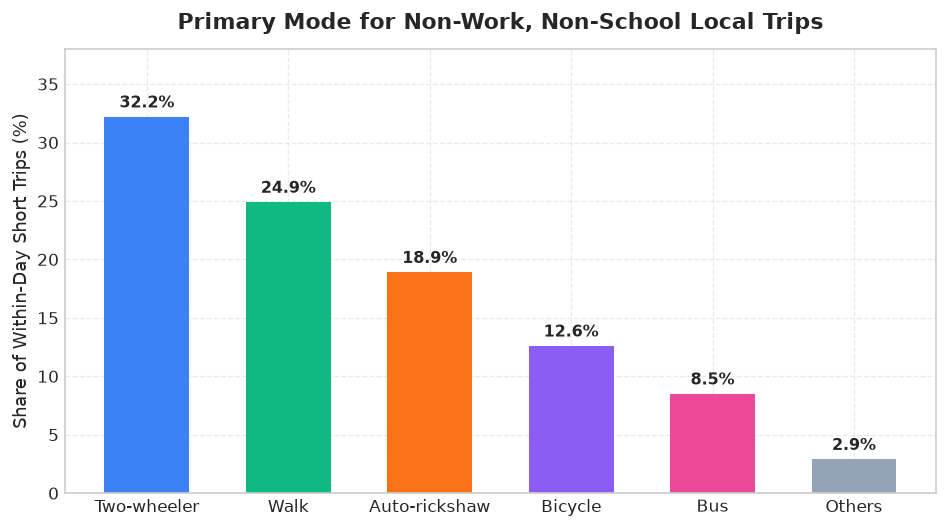

In [20]:
daily_modes = {
    "Transport Mode": ["Two-wheeler", "Walk", "Auto-rickshaw", "Bicycle", "Bus", "Others"],
    "Trip Share (%)": [32.2, 24.9, 18.9, 12.6, 8.5, 2.9]
}
df_daily_modes = pd.DataFrame(daily_modes)

table5_purposes = {
    "Trip Purpose": [
        "Unpaid domestic services for household members",
        "Socializing, communication and religious activities",
        "Self-care and maintenance",
        "Own use production of goods",
        "Unpaid caregiving services for household members",
        "Learning",
        "Culture, leisure, sports practice, tourism",
        "Seeking employment / setting up business",
        "Unpaid volunteering, training, work"
    ],
    "Rural (%)": [51.5, 6.4, 4.4, 2.0, 2.2, 1.0, 0.7, 0.5, 0.2],
    "Urban (%)": [60.1, 7.5, 5.0, 1.5, 2.2, 1.3, 1.4, 0.4, 0.2],
    "Rural+Urban (%)": [54.1, 6.8, 4.6, 1.8, 2.2, 1.1, 0.9, 0.5, 0.2]
}
df_daily_purp = pd.DataFrame(table5_purposes).set_index("Trip Purpose")
display(df_daily_purp)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(df_daily_modes["Transport Mode"], df_daily_modes["Trip Share (%)"], 
              color=["#3b82f6", "#10b981", "#f97316", "#8b5cf6", "#ec4899", "#94a3b8"], width=0.6)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 0.8, f"{yval:.1f}%", 
            ha='center', fontweight='bold', fontsize=9.5)

ax.set_ylabel("Share of Within-Day Short Trips (%)")
ax.set_title("Primary Mode for Non-Work, Non-School Local Trips", pad=12)
ax.set_ylim(0, 38)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig7_daily_short_trips.png", dpi=300)
plt.show()


## 10. Consolidated Benchmark Dashboard & Export

Consolidated summary matrix containing all 26 headline indicators and automated CSV exports.


In [21]:
summary_indicators = [
    {"Domain": "Worker Commute", "Indicator": "Two-Wheeler Primary Mode Share", "Rural": "37.1%", "Urban": "52.3%", "All-India": "42.6%"},
    {"Domain": "Worker Commute", "Indicator": "Walking Share", "Rural": "36.6%", "Urban": "13.5%", "All-India": "28.3%"},
    {"Domain": "Worker Commute", "Indicator": "Bicycle Share", "Rural": "13.4%", "Urban": "5.8%", "All-India": "10.7%"},
    {"Domain": "Worker Commute", "Indicator": "Urban Mass Transit (Metro/Suburban/Tram)", "Rural": "0.4%", "Urban": "5.0%", "All-India": "2.1%"},
    {"Domain": "Worker Commute", "Indicator": "Average Commute Duration", "Rural": "23 min", "Urban": "27 min", "All-India": "25 min"},
    {"Domain": "Worker Commute", "Indicator": "Commute Reached in <= 30 mins", "Rural": "86.1%", "Urban": "79.3%", "All-India": "83.4%"},
    {"Domain": "Worker Commute", "Indicator": "Peak Morning Departure Rush (8-10 AM)", "Rural": "54.4%", "Urban": "59.8%", "All-India": "56.5%"},
    {"Domain": "Worker Commute", "Indicator": "Average Monthly Commute Spend", "Rural": "₹612", "Urban": "₹1,044", "All-India": "₹785"},
    {"Domain": "Worker Commute", "Indicator": "Male Worker Monthly Commute Spend", "Rural": "₹674", "Urban": "₹1,076", "All-India": "₹835"},
    {"Domain": "Worker Commute", "Indicator": "Female Worker Monthly Commute Spend", "Rural": "₹307", "Urban": "₹884", "All-India": "₹533"},
    {"Domain": "Student Commute", "Indicator": "Walking Primary Mode Share (Age 6+)", "Rural": "N/A", "Urban": "N/A", "All-India": "37.0%"},
    {"Domain": "Student Commute", "Indicator": "Walking Primary Share (Age 6-14)", "Rural": "N/A", "Urban": "N/A", "All-India": "47.3%"},
    {"Domain": "Student Commute", "Indicator": "Bus Primary Mode Share (Age 6+)", "Rural": "N/A", "Urban": "N/A", "All-India": "29.5%"},
    {"Domain": "Student Commute", "Indicator": "Bicycle Primary Share (Age 15-29)", "Rural": "N/A", "Urban": "N/A", "All-India": "21.4%"},
    {"Domain": "Student Commute", "Indicator": "Average Commute Duration", "Rural": "23 min", "Urban": "22 min", "All-India": "23 min"},
    {"Domain": "Student Commute", "Indicator": "Commute Reached in <= 30 mins", "Rural": "86.6%", "Urban": "89.6%", "All-India": "87.6%"},
    {"Domain": "Student Commute", "Indicator": "Peak Departure Window (8-9 AM)", "Rural": "N/A", "Urban": "N/A", "All-India": "35.7%"},
    {"Domain": "Student Commute", "Indicator": "Average Monthly Commute Spend", "Rural": "₹361", "Urban": "₹617", "All-India": "₹443"},
    {"Domain": "Overnight Travel", "Indicator": "Bus Share of Overnight Trips", "Rural": "N/A", "Urban": "N/A", "All-India": "55.8%"},
    {"Domain": "Overnight Travel", "Indicator": "Railways Share of Overnight Trips", "Rural": "14.0%", "Urban": "22.7%", "All-India": "17.7%"},
    {"Domain": "Overnight Travel", "Indicator": "Combined Public Transit (Bus+Rail)", "Rural": "N/A", "Urban": "N/A", "All-India": "73.5%"},
    {"Domain": "Overnight Travel", "Indicator": "Social & Religious Purpose Share", "Rural": "69.7%", "Urban": "70.9%", "All-India": "70.2%"},
    {"Domain": "Overnight Travel", "Indicator": "Culture, Leisure & Tourism Share", "Rural": "6.2%", "Urban": "9.3%", "All-India": "7.4%"},
    {"Domain": "Overnight Travel", "Indicator": "Sample Mean Spend per Special Trip", "Rural": "N/A", "Urban": "N/A", "All-India": "₹18,784"},
    {"Domain": "Daily Short Trips", "Indicator": "Two-Wheeler Primary Share", "Rural": "N/A", "Urban": "N/A", "All-India": "32.2%"},
    {"Domain": "Daily Short Trips", "Indicator": "Walking Share", "Rural": "N/A", "Urban": "N/A", "All-India": "24.9%"}
]

df_summary = pd.DataFrame(summary_indicators)
display(df_summary)

df_summary.to_csv(OUTPUT_DIR / "nhts_report_key_indicators.csv", index=False)
df_worker_modes.to_csv(OUTPUT_DIR / "table4_worker_modes.csv")
df_student_modes.to_csv(OUTPUT_DIR / "table2_student_modes.csv")
df_daily_purp.to_csv(OUTPUT_DIR / "table5_daily_trip_purposes.csv")
df_costs.to_csv(OUTPUT_DIR / "fig5_monthly_commute_costs.csv")
df_seasonality.to_csv(OUTPUT_DIR / "tourism_seasonality.csv", index=False)
df_top_states.to_csv(OUTPUT_DIR / "top_destination_states.csv", index=False)
df_spend_categories.to_csv(OUTPUT_DIR / "spend_categories.csv", index=False)

print(f"\nSuccessfully exported all 8 benchmark indicator tables to '{OUTPUT_DIR.resolve()}'!")


,Domain,Indicator,Rural,Urban,All-India
0,Worker Commute,Two-Wheeler Primary Mode Share,37.1%,52.3%,42.6%
1,Worker Commute,Walking Share,36.6%,13.5%,28.3%
2,Worker Commute,Bicycle Share,13.4%,5.8%,10.7%
3,Worker Commute,Urban Mass Transit (Metro/Suburban/Tram),0.4%,5.0%,2.1%
4,Worker Commute,Average Commute Duration,23 min,27 min,25 min
5,Worker Commute,Commute Reached in <= 30 mins,86.1%,79.3%,83.4%
6,Worker Commute,Peak Morning Departure Rush (8-10 AM),54.4%,59.8%,56.5%
7,Worker Commute,Average Monthly Commute Spend,₹612,"₹1,044",₹785
8,Worker Commute,Male Worker Monthly Commute Spend,₹674,"₹1,076",₹835
9,Worker Commute,Female Worker Monthly Commute Spend,₹307,₹884,₹533



Successfully exported all 8 benchmark indicator tables to '/Users/shubham/CODE/Projects/Data/Indian Travel /output'!
